# Model Diagnostics
## Environmental Statistics 6
C.F. Dormann

There are two thing to learn today: 
  * How to simulate data from a fitted model.
  * Using such simulations for model diagnostics.

## 1 Exercise 1: Model diagnostics for the linear model
Use `invented` data (aka simulated or synthetic data), as we then know the truth. For this example, we invent a data set and misspecify the model in order for the model diagnostics to identify a problem.

*  Specifically, we define two variables, $x_1$ and $x_2$ (both uniform between 0 and 1), and how they affect the response $y$, e.g. $y = 0.7x_1 + 2.5x_2 - 2.5x_2^2 + \varepsilon$ (with $\varepsilon$ = 0.1). To make this fully reproducible, we use a random number seed (`random.seed()`). 

*  Analyse these data using a correctly specified (G)LM (i.e. with predictors as used for the simulation, but with the coefficients to be estimated from the data).

*  Instead of the correct model structure, we want to use a misspecified model. Simply omit the quadratic effect, and look at the model output:

*  The model still looks fine on paper, but now use the four standard model diagnostic plots for the lm to investigate whether it actually is fine (The 4 plots are: Residuals vs. Fitted, Q-Q plot, Scale-location plot, and Standardized residuals vs. leverage plot). As a bonus you can add the plot of Cook's distances versus row labels. Put them into a single figure); do the plots look alright?


Let us still run with this model and see where we get to.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.graphics.regressionplots as pltreg
from scipy.stats import norm, uniform, kstest, probplot
from statsmodels.distributions.empirical_distribution import ECDF

import os
os.environ["R_HOME"] = r"C:\Users\ia1015\.conda\envs\envstats\lib\R"

import warnings


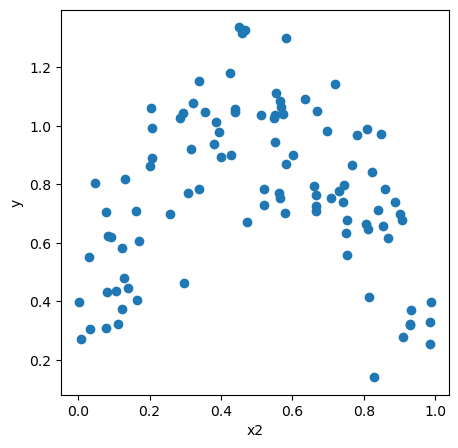

In [3]:
np.random.seed(123)

x1 = np.random.uniform(0, 1, 100)
x2 = np.random.uniform(0, 1, 100)
y = 0.7 * x1 + 2.5 * x2 - 2.5 * x2**2 + np.random.normal(0, 0.1, 100)

plt.figure(figsize=(5,5))
plt.scatter(x2, y)
plt.xlabel('x2')
plt.ylabel('y')
plt.show()


Note that the relationship between $y$ and $x_2$ is not particularly clear, since the effect of $x_1$ is added on top of it. The analysis will be great, though:

In [26]:
data = pd.DataFrame({'y': y, 'x1': x1, 'x2': x2})

fm = sm.OLS.from_formula('y ~ x1 + x2 + I(x2**2)', data=data).fit()
print(fm.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.887
Model:                            OLS   Adj. R-squared:                  0.884
Method:                 Least Squares   F-statistic:                     252.3
Date:                Tue, 18 Nov 2025   Prob (F-statistic):           2.16e-45
Time:                        12:40:40   Log-Likelihood:                 96.259
No. Observations:                 100   AIC:                            -184.5
Df Residuals:                      96   BIC:                            -174.1
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0057      0.034     -0.167      0.8

Instead of the correct model structure, we want to use a misspecified model. In this case, we simply omit the quadratic effect.

In [5]:
fmwrong = sm.OLS.from_formula('y ~ x1 + x2', data=data).fit()
print(fmwrong.summary())


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.389
Method:                 Least Squares   F-statistic:                     32.48
Date:                Tue, 18 Nov 2025   Prob (F-statistic):           1.59e-11
Time:                        11:17:18   Log-Likelihood:                 12.673
No. Observations:                 100   AIC:                            -19.35
Df Residuals:                      97   BIC:                            -11.53
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.3789      0.065      5.814      0.0

The model still looks fine on paper, but now we will use the four standard model diagnostic plots for the linear model to investigate whether it actually is fine:

In [6]:
# Get influence measures 
influence = fmwrong.get_influence()

model_frame = influence.summary_frame()
model_frame

,dfb_Intercept,dfb_x1,dfb_x2,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
0,-0.016878,0.049277,0.006293,0.002086,0.612182,0.016422,0.079103,0.610198,0.078847
1,0.040125,-0.054697,0.032241,0.002936,0.655606,0.020082,0.093853,0.653668,0.093575
2,-0.111820,0.067353,0.081231,0.004397,-0.526568,0.045409,-0.114846,-0.524597,-0.114417
3,0.018395,0.001437,-0.022871,0.000284,0.174171,0.027355,0.029209,0.173298,0.029062
4,0.007793,0.066046,-0.044704,0.004438,0.786488,0.021071,0.115388,0.784930,0.115159
...,...,...,...,...,...,...,...,...,...
95,-0.046280,0.069923,0.045424,0.004568,0.844295,0.018861,0.117061,0.843035,0.116887
96,-0.223781,0.143263,0.162496,0.017081,-0.874173,0.062841,-0.226368,-0.873102,-0.226090
97,0.003619,-0.014172,0.033498,0.001058,0.413155,0.018256,0.056340,0.411382,0.056098
98,0.051299,-0.046354,-0.009145,0.001353,0.427489,0.021728,0.063710,0.425681,0.063440


In [7]:
std_residuals = fmwrong.get_influence().resid_studentized_external # student_resid
std_residuals

array([ 0.61019811,  0.65366816, -0.52459744,  0.17329767,  0.78492973,
        0.34541535, -0.7500396 ,  0.98085519, -0.54085225,  1.54936424,
        1.30224922,  0.58566915, -0.44525678, -1.57957584,  0.46599414,
        0.45713895,  0.73996686,  1.17712118, -1.72601957, -2.00647497,
       -0.97403285, -0.02083084,  0.6085644 , -0.54371759, -1.17282573,
       -1.97578354,  0.20755336,  0.82719698,  0.13480291,  0.58502049,
        1.36584662,  0.05630377,  0.82817138, -0.78228936, -1.96622052,
       -1.40753082,  0.89316497,  0.14600412,  1.22135257,  1.20496993,
       -0.98216394, -0.08411761, -1.5996934 ,  1.66901537,  1.3772037 ,
        0.34595807, -0.12517803, -1.34520053, -0.17432379, -0.72478608,
       -0.32577854, -0.21260706,  0.942621  , -0.07054248,  0.21814978,
       -1.32308347,  0.04241134, -0.84426866, -0.29952133,  1.30201749,
        0.8203074 ,  0.11025806,  1.04841819, -1.14286654,  1.34756225,
       -0.33270665,  0.97447855, -1.37034134,  0.33099548,  1.01

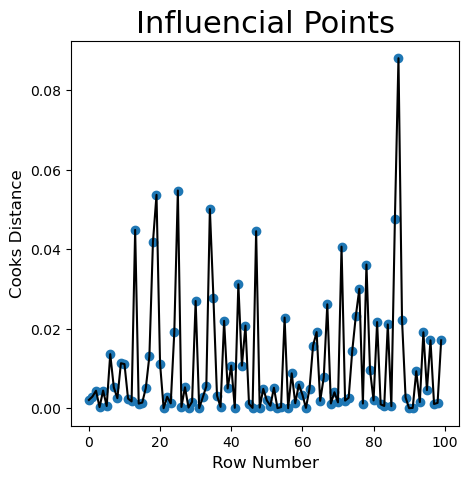

In [17]:
cooks = model_frame.cooks_d

plt.figure(figsize = (5, 5))
plt.scatter(data.index, cooks)
plt.plot(data.index, cooks, color='black')
plt.xlabel('Row Number', fontsize = 12)
plt.ylabel('Cooks Distance', fontsize = 12)
plt.title('Influencial Points', fontsize = 22)
plt.show()

mean_cooks = np.mean(cooks[0])

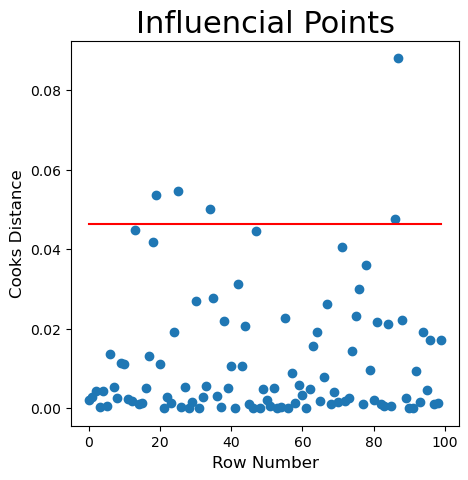

In [16]:
mean_cooks = np.mean(cooks)

mean_cooks_list = [4*mean_cooks for i in data.index]

plt.figure(figsize = (5, 5))
plt.scatter(data.index, cooks)
plt.plot(data.index, mean_cooks_list, color="red")
plt.xlabel('Row Number', fontsize = 12)
plt.ylabel('Cooks Distance', fontsize = 12)
plt.title('Influencial Points', fontsize = 22)
plt.show()

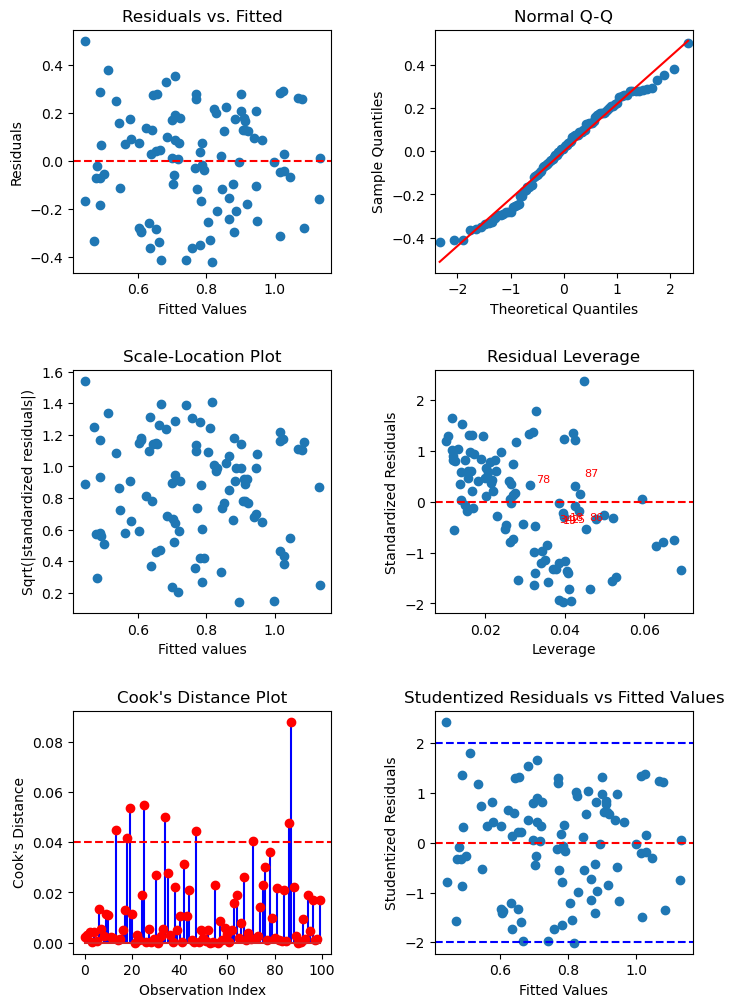

In [8]:
fig = plt.figure(figsize=(8, 12))
grid = plt.GridSpec(3, 2, wspace=0.4, hspace=0.4)

# Create subplots in the grid
#ax1 = fig.add_subplot(grid[0, 0])  # First row, first column
#ax2 = fig.add_subplot(grid[0, 1])  # First row, second column
#ax3 = fig.add_subplot(grid[1, 0])  # Second row, first column
#ax4 = fig.add_subplot(grid[1, 1])  # Second row, second column
#ax5 = fig.add_subplot(grid[2, 0])  # Third row, first column
#ax6 = fig.add_subplot(grid[2, 1])  # Third row, second column

# Residuals vs. Fitted plot
ax1 = fig.add_subplot(grid[0, 0])
ax1.scatter(fmwrong.fittedvalues, fmwrong.resid)  # all resid based on function used: fmwrong.resid_response if using sm.GLM
ax1.axhline(y = 0, color = 'r', linestyle = '--') 
ax1.set_xlabel('Fitted Values')
ax1.set_ylabel('Residuals')
ax1.set_title('Residuals vs. Fitted')


# Normal Q-Q plot
ax2 = fig.add_subplot(grid[0, 1])
sm.qqplot(fmwrong.resid, line='r', ax=ax2)
ax2.set_title('Normal Q-Q')


ax3 = fig.add_subplot(grid[1, 0])
#std_residuals = (residuals - np.mean(residuals)) / np.std(residuals) #using raw residuals
std_residuals = model_frame.standard_resid
sqrt_stdized_resid = np.sqrt(np.abs(std_residuals))

ax3.scatter(fmwrong.fittedvalues, sqrt_stdized_resid)
ax3.set_xlabel('Fitted values')
ax3.set_ylabel('Sqrt(|standardized residuals|)')
ax3.set_title('Scale-Location Plot')


# Extract leverage values
leverage = model_frame.hat_diag  #fmwrong.get_influence().hat_matrix_diag 

# Create a residual vs leverage plot
ax4 = fig.add_subplot(grid[1, 1])
ax4.scatter(leverage, std_residuals)
ax4.axhline(y = 0, color = 'r', linestyle = '--') 
ax4.set_xlabel('Leverage')
ax4.set_ylabel('Standardized Residuals')
ax4.set_title('Residual Leverage')


# Annotate influential points (optional)
threshold = 2 * np.mean(np.abs(fmwrong.resid))
influential_points = np.where(np.abs(fmwrong.resid) > threshold)[0]
for i in influential_points:
    ax4.annotate(i, (leverage[i], fmwrong.resid[i]), color='red',fontsize=8)

# Extract Cook's Distance
distance = model_frame.cooks_d

# Plot Cook's Distance
ax5 = fig.add_subplot(grid[2, 0])
ax5.stem(range(len(distance)), distance, linefmt='b-', markerfmt='ro')
ax5.axhline(4 / len(distance), color='red', linestyle='--')
ax5.set_xlabel("Observation Index")
ax5.set_ylabel("Cook's Distance")
ax5.set_title("Cook's Distance Plot")


# Plot Studentized Residuals vs Fitted Values
ax6 = fig.add_subplot(grid[2, 1])
ax6.scatter(fmwrong.fittedvalues, model_frame.student_resid)
ax6.axhline(y=0, color='red', linestyle='--')
ax6.axhline(y=2, color='blue', linestyle='--')
ax6.axhline(y=-2, color='blue', linestyle='--')
ax6.set_xlabel('Fitted Values')
ax6.set_ylabel('Studentized Residuals')
ax6.set_title('Studentized Residuals vs Fitted Values')


plt.show()


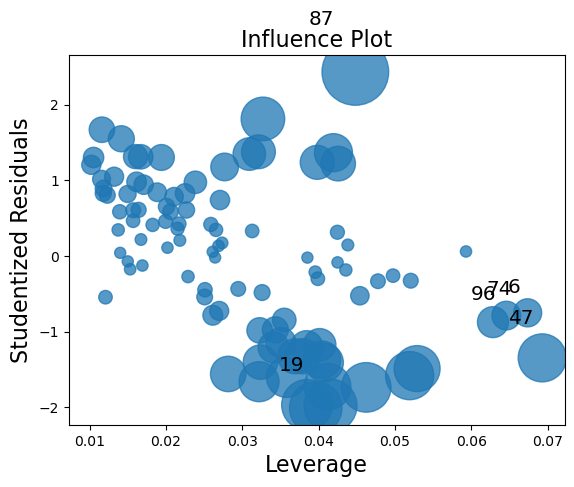

In [9]:
from statsmodels.graphics.regressionplots import influence_plot

influence_plot(fmwrong)
plt.show()

**1. Low Leverage, Low Residuals:**
Points with low leverage and low residuals are typically well-behaved data points that do not strongly influence the model and have small deviations from the model's predictions.

**2. Low Leverage, High Residuals (Outliers):**
Points with low leverage but high residuals are potential outliers. These are data points that deviate significantly from the model predictions but do not have a strong influence on the model fit.

**3. High Leverage, Low Residuals (Influential Points):**
Points with high leverage and low residuals are influential points. These observations have a strong influence on the model fit, pulling the regression line toward them.

**4. High Leverage, High Residuals (Highly Influential Outliers):**
Points with both high leverage and high residuals are potentially highly influential outliers. These points can significantly affect both the model fit and predictions.

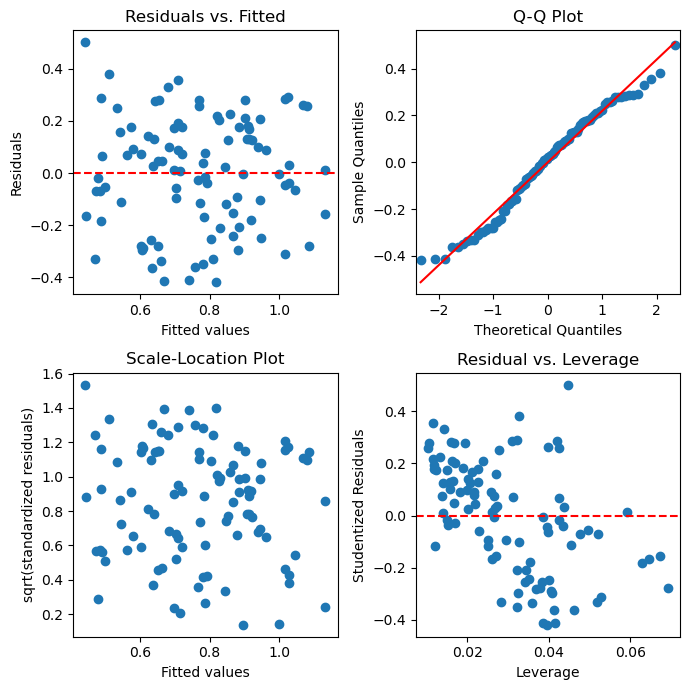

In [10]:
# similarly:

# Get residuals and fitted values
residuals = fmwrong.resid  # this is fmwrong.resid_response if using sm.GLM
fitted_values = fmwrong.fittedvalues

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(7, 7))

# Residuals vs. Fitted plot
axes[0, 0].scatter(fitted_values, residuals)
axes[0, 0].axhline(y = 0, color = 'r', linestyle = '--') 
axes[0, 0].set_xlabel('Fitted values')
axes[0, 0].set_ylabel('Residuals')
axes[0, 0].set_title('Residuals vs. Fitted')

# Q-Q plot of residuals
sm.qqplot(residuals, line='r', ax=axes[0, 1])
axes[0, 1].set_title('Q-Q Plot')


# Scale-location plot (square root of standardized residuals vs. fitted values)
sqrt_std_residuals = np.sqrt(np.abs((residuals - np.mean(residuals)) / np.std(residuals)))
axes[1, 0].scatter(fitted_values, sqrt_std_residuals)
axes[1, 0].set_xlabel('Fitted values')
axes[1, 0].set_ylabel('sqrt(standardized residuals)')
axes[1, 0].set_title('Scale-Location Plot')

# Get residuals and leverage
influence = fmwrong.get_influence()
leverage = influence.hat_matrix_diag

# Create Residual vs. Leverage plot

axes[1, 1].scatter(leverage, residuals)
axes[1, 1].set_xlabel('Leverage')
axes[1, 1].set_ylabel('Studentized Residuals')
axes[1, 1].set_title('Residual vs. Leverage')
axes[1, 1].axhline(y=0, color='r', linestyle='--')


# Adjust layout to prevent overlapping
plt.tight_layout()

# Show the plot
plt.show()

This still looks, more or less, okay. In the second panel there is a kink in the quantile-quantile-plot, but not dramatic. The third is fine. The fourth plot look decidedly odd, with a clear pattern between residual values and their impact on the regression estimates (`leverage`). Still, none of these plots is strongly suggestive of a quadratic trend missing in the model.
The data points with a Cook's distance greater than the threshold suggests that the point substantially affects the fitted regression model. These points are typically the ones that are far from the mean of the predictor variables and/or have large residuals. Studentized residuals more useful for detecting outliers and influential points compared to unadjusted residuals. Residuals between -2 and 2: These are considered acceptable and suggest that the model is performing reasonably well for these points. 

Note: Cook's distance and studentized residuals are different diagnostic measures, and they are not necessarily going to highlight the same data points as influential.
-  Cook's Distance flags points that have high influence on the model (due to a combination of large residuals and high leverage).
-  Studentized Residuals flag points that have large residuals but do not take leverage into account as directly

Let us still run with this model and see where we get to.




## 2 Exercise 2: Simulating data from a GLM
The point now is to invent a new response vector, $y_\text{sim}$, from the fitted model. That is, given our values for $x_1$ and $x_2$, and the fitted coefficients, and the residual noise $\varepsilon$, what *could* the data set have looked like? We’ll go through it in several step.

### 2.1 Simulation by foot
Remember that the analytical computation of the predicted value is simply a matrix multiplication $\hat{y}=Xb$. Note, however, that $X$ contains a column of 1s for the intercept.

In [11]:
# Create the design matrix X
X = np.column_stack((np.ones_like(x1), x1, x2)) #np.ones(len(x1))

# Get the coefficients from the model fmwrong
beta = fmwrong.params
sd = np.sqrt(fmwrong.scale) # OR np.sqrt(fmwrong.mse_resid) :residual std error from summary of the model

# Generate new observations based on the linear combination and added noise
newy = np.dot(X, beta) + np.random.normal(0, sd, 100)
print(newy)

[1.21143517 0.4909625  0.26135611 0.63540664 1.18543039 0.41281869
 0.9417907  0.75634933 0.50210862 0.42536594 0.31415059 0.82064796
 0.62540102 0.32290442 0.32527444 1.20985327 0.25582645 0.59526743
 0.52601578 0.96183239 1.09238789 0.80779196 0.4971615  0.99660183
 1.35416633 0.75773981 0.68725878 0.75276209 0.80201618 0.67338891
 0.34531621 0.830418   0.69097405 1.06766298 0.58876499 0.76906156
 0.78288094 1.00157952 1.33427843 0.91688183 0.61246499 0.61763682
 0.95800087 0.68058425 0.97075986 0.45743868 0.76480755 1.23404572
 0.61483946 0.57483393 0.39356822 0.7165685  0.93974438 0.6939191
 0.2831233  0.52723072 0.67437116 1.01517089 1.01378991 1.17392446
 0.77051608 0.82909589 0.8363437  0.80453566 1.04570756 0.60372364
 1.23422835 0.26818325 0.45160121 0.7247529  0.6947643  0.93857011
 0.46748982 0.96309196 0.43702713 0.84989642 0.55620473 0.87270251
 0.44178214 0.85992451 0.44503001 0.67875136 0.52205442 0.61957727
 0.85994711 1.47283691 0.22582477 0.19850319 0.56483607 0.84348

This would be one new data set, as could be expected from the model estimates. Compute the correlation with the actual data. Is it well correlated? How well would you expect it to be correlated?

In [78]:
# Calculate the correlation coefficient
correlation_coefficient = np.corrcoef(newy, y)[0, 1]

print(f"Correlation coefficient between newy and y: {correlation_coefficient}")

Correlation coefficient between newy and y: 0.4202951638497612


And it is not well correlated. How well *should* it be correlated? Well, on average the correlation should be similar to the R$^2$ of the fitted model: the better the model, the less room there is for simulating the new response.

We can simulate not one but, say, 326 such data sets. I show you two ways to do so, one using a the previous `np.random.normal(0, sd, size=(326, 100)` and the other a `for`-loop:

In [20]:
# Simulate responses based on the model assumptions
np.random.seed(234)

# np.random.normal(0, resid_std, size=(num_simulations, len(fit.resid))
newy1 = np.dot(X, beta) + np.random.normal(0, sd, size=(326, 100))
newy1 = newy1.T

# Print the dimensions of simulated_responses
print("Dimensions of newY:", newy1.shape)

#newy1

Dimensions of newY: (100, 326)


In [11]:
# using for-loop

np.random.seed(234)
num_replicates = 326
num_observations = 100

# Create an array to store replicate newy values
newy2 = np.zeros((num_observations,num_replicates))

# Generate replicates
for i in range(num_replicates):
    newy2[:, i] = np.dot(X, beta) + np.random.normal(0, sd, num_observations)
    
print("Dimensions of newY:", newy2.shape)

#newy2

Dimensions of newY: (100, 326)


The first approach is simpler (and marginally faster), but less well readable. Note the two approaches are perfectly reproducible, and they yield the same `newY`.

A third way to simulate data from a model is as follows:

In [12]:
np.random.seed(234)
newy3_list = [np.dot(X, fmwrong.params) + np.random.normal(0, sd, size=(100)) for _ in range(326)]
newy3 = np.array(newy3_list).T

print("Dimensions of newY:", newy3.shape)

#newy3

Dimensions of newY: (100, 326)


Either of these three will do.

## 3 Exercise 3: Simulating residuals

### 3.1  The probability integral transform with known source distribution
We can convert observations such that they follow a uniform distribution. First, we assume that we know from which distribution the data derive. 
Compute quantiles for the residual, assuming a normal distribution (with mean and sd from the model residuals). Make histogram of the quantiles and add a uniform distribution (U(0,1)) as curve.

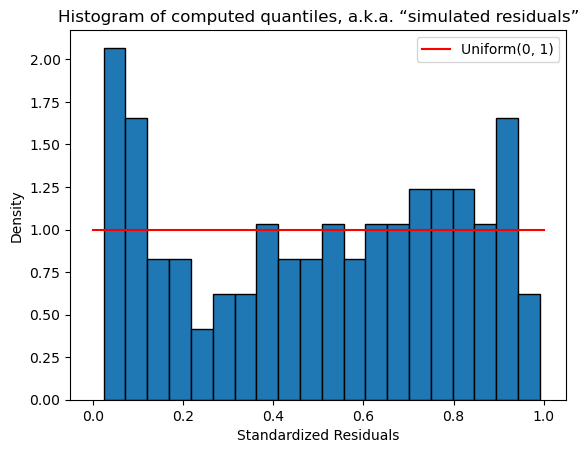

In [22]:
resids = fmwrong.resid
# Standardized residuals
std_residuals = model_frame.standard_resid

plt.hist(norm.cdf(std_residuals), bins=20, density=True, edgecolor='black')

x = np.linspace(0, 1, 100)
plt.plot(x, uniform.pdf(x, 0, 1), 'r', label='Uniform(0, 1)')
plt.xlabel('Standardized Residuals')
plt.ylabel('Density')
plt.title('Histogram of computed quantiles, a.k.a. “simulated residuals”')
plt.legend()
plt.show()



What happened here was that we converted the observed residual into a quantile of the normal distribution. And the above-mentioned probability integral transform demands that these quantiles are uniform (horizontal line is the expectation for such a uniform distribution).

### 3.2 The probability integral transform *without* distributional assumption
We now drop the distributional assumption, and use the simulations as forming the distribution from which the data were derived.

Plot the empirical cumulative density distribution for the simulations of the first data point, and indicate the first data points value and its quantile (using `abline`).


In [21]:
ECDF(newy1[0,])(y[0])

0.7484662576687117

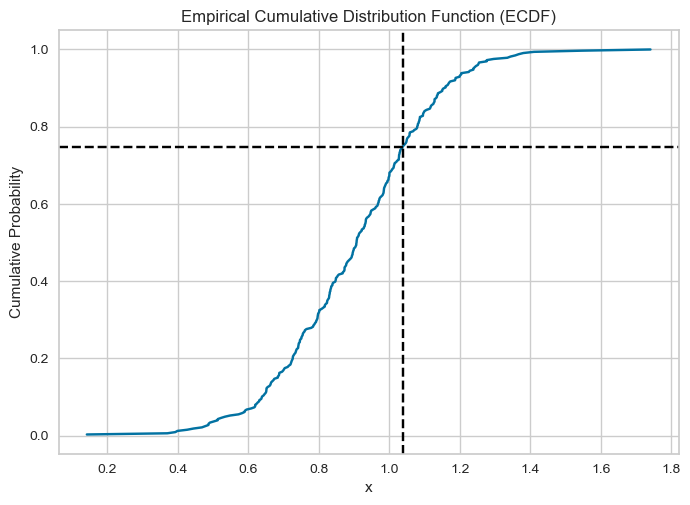

In [85]:
ecdf = ECDF(newy1[0,])
ecdf_value = ecdf(y[0])
#print(ecdf_value)

plt.plot(ecdf.x, ecdf.y, label='ECDF of newY[1,]')
plt.axvline(y[0], color='black', linestyle='--')
plt.axhline(ecdf_value, color='black', linestyle='--')
plt.xlabel('x')
plt.ylabel('Cumulative Probability')
plt.title('Empirical Cumulative Distribution Function (ECDF)')
plt.show()


The function  `ecdf` is a bit funny. It actually returns a function, not a value. Hence we can directly use the resulting function to compute a value, namely the quantile of a value in that ECDF. That's why we have in the code this funny construct of two successife sets of brackets.


Now, compute this quantile for all data points within their simulations, possibly using a `for`-loop. The plot a histogram of these quantiles.

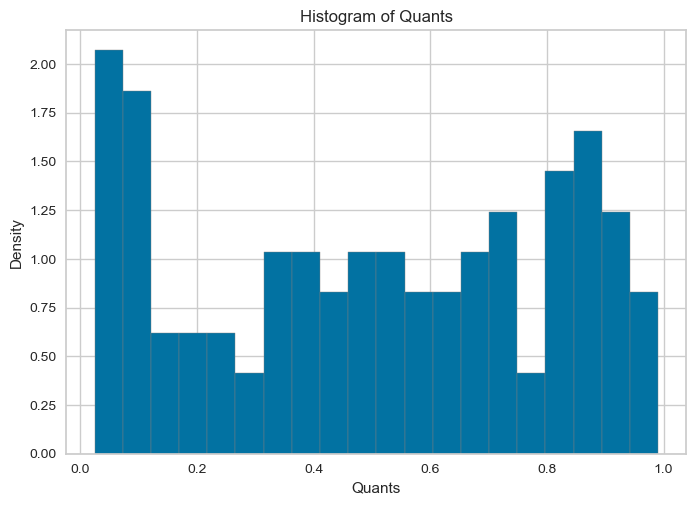

In [86]:
# a bit complicated way:
quants = np.zeros_like(y, dtype=float)
for i in range(len(y)):
    ecdf_i = np.searchsorted(np.sort(newy1[i, :]), y[i], side='right') / newy1.shape[1]
    quants[i] = ecdf_i

plt.hist(quants, bins=20, density=True, edgecolor='grey')

# Add labels and title
plt.xlabel('Quants')
plt.ylabel('Density')
plt.title('Histogram of Quants')

# Show the plot
plt.show()

In [30]:
quants = [ECDF(newy1[i,])(y[i]) for i in range(len(y))]
len(quants)

100

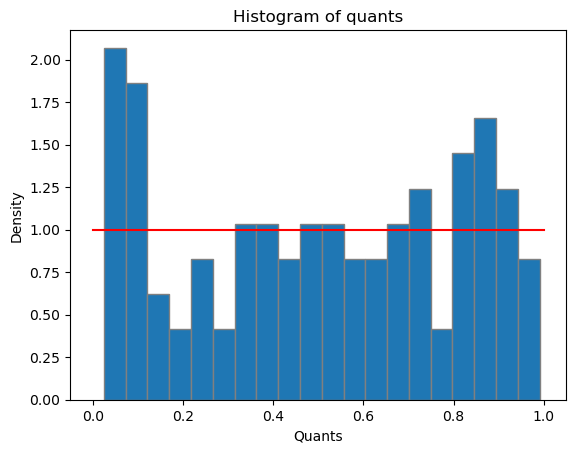

In [23]:
# simpliest way to do this

quants = [ECDF(newy1[i,])(y[i]) for i in range(len(y))]

plt.hist(quants, bins=20, density=True, edgecolor='grey')
plt.plot(x, uniform.pdf(x, 0, 1), 'r', label='Uniform(0, 1)')
plt.xlabel('Quants')
plt.ylabel('Density')
plt.title('Histogram of quants')
plt.show()

We notice that this looks very similar to the probability integral transform above. So we now have a non-parametric way to achieve the same thing: convert a data set into quantiles of what would be expected from the model.

The final step is to plot these quantiles, which we will start referring to as `simulated residuals`, against the predicted value, to look for patterns. Also, do a formal Kolmogorov-Smirnov-test whether these data deviate from a standard uniform distribution that they are supposed to conform to.

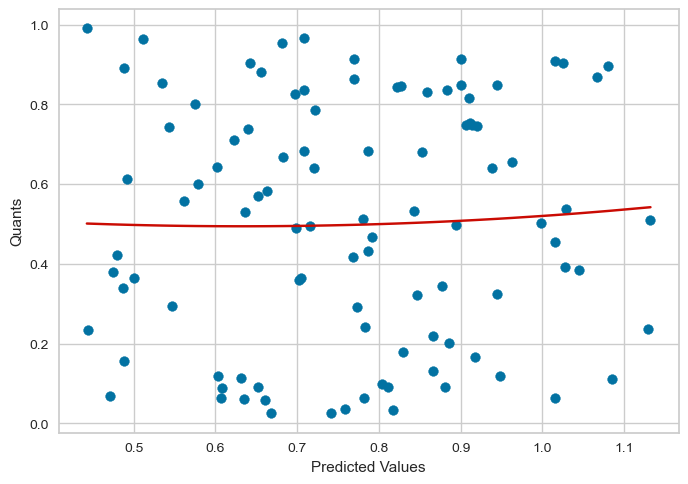

Kolmogorov-Smirnov test
KS Statistic: 0.0703680981595092
KS p-value: 0.6784687658516599


In [100]:
predicted = fmwrong.predict()

sorted_indices = np.argsort(predicted)
sorted_predicted = predicted[sorted_indices]
sorted_quants = np.array(quants)[sorted_indices]

plt.scatter(sorted_predicted, sorted_quants)
#z = np.polyfit(sorted_predicted, sorted_quants, 2)
#p = np.poly1d(z)
plt.plot(sorted_predicted, p(sorted_predicted), 'r')
plt.xlabel('Predicted Values')
plt.ylabel('Quants')
plt.show()

print("Kolmogorov-Smirnov test")
ks_statistic, ks_p_value = kstest(quants, "uniform")
print("KS Statistic:", ks_statistic)
print("KS p-value:", ks_p_value)

This plot is rather similar to those returned by the diagnostics plot of the original linear model. However, we now have a pipeline in place to do this for *any* kind of model, not only for the linear; as long as we can simulate from that model.



## 4 Exercise 4: DHARMa
The R-package to do this for us is called **DHARMa** and was put together by Florian Hartig (Uni Regensburg). It is extremely useful and adds a few more tests to the simulations and figures presented above. However, there's no equivalent in python, so they plot must be done indivually. Here we present the plots for the model `fmwrong`, where we plot the QQ plot residuals and the Residual vs predicted plot.

### 4.1 DHARMa automatisch
Use DHARMa with the model fmwrong, accepting all its default values. The key functions to use are `simulateResiduals` and `plot` for the resulting object.

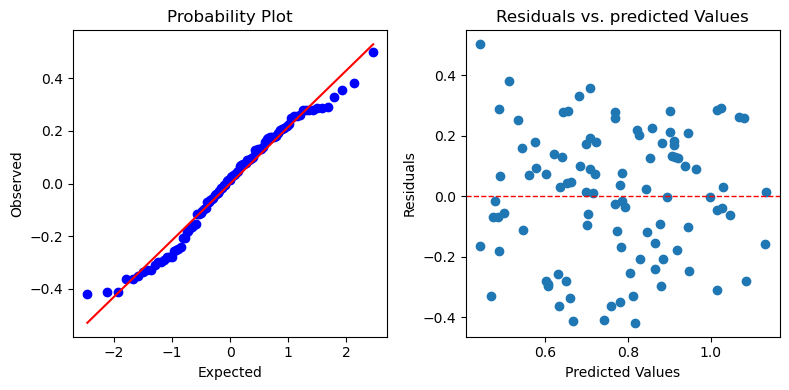

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].set_title('QQ plot residuals')
probplot(fmwrong.resid, plot=axes[0])
axes[0].set_xlabel('Expected')
axes[0].set_ylabel('Observed')

axes[1].set_title('Residuals vs. predicted Values')
axes[1].scatter(predicted, fmwrong.resid)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_xlabel('Predicted Values')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()


We can also switch to R and see what it looks like with the DHARMa package in R

In [90]:
%load_ext rpy2.ipython

C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\rpy2\robjects\packages.py:367: UserWarning: The symbol 'quartz' is not in this R namespace/package.
  warnings.warn(


In [91]:
%%R
suppressWarnings(install.packages("DHARMa"))
library(DHARMa)

Exception ignored from cffi callback <function _consolewrite_ex at 0x000001FF7F650720>:
Traceback (most recent call last):
  File "C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\rpy2\rinterface_lib\callbacks.py", line 133, in _consolewrite_ex
    s = conversion._cchar_to_str_with_maxlen(buf, n, _CCHAR_ENCODING)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\rpy2\rinterface_lib\conversion.py", line 138, in _cchar_to_str_with_maxlen
    s = ffi.string(c, maxlen).decode(encoding)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
UnicodeDecodeError: 'utf-8' codec can't decode byte 0xfc in position 36: invalid start byte
R[write to console]: This is DHARMa 0.4.6. For overview type '?DHARMa'. For recent changes, type news(package = 'DHARMa')



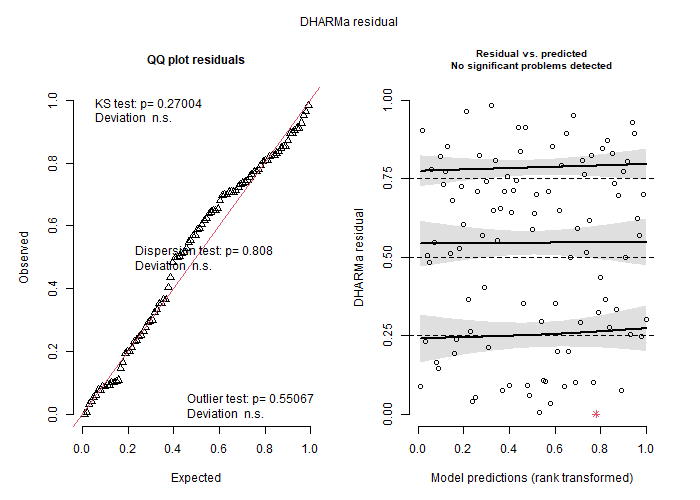

In [96]:
%%R -w 700 -h 500 
set.seed(123)
x1 <- runif(100, 0, 1)
x2 <- runif(100, 0, 1)
y <- 0.7*x1 + 2.5*x2 - 2.5*x2^2 + rnorm(100, mean=0, sd=0.1)

fmwrong <- lm(y ~ x1 + x2)


sim <- simulateResiduals(fmwrong, plot=T)


### 4.2 DHARMa mit eigenen Simulationen
If the model type is not supported by DHARMa, we can still use its functionality by providing our own simulations,
using createDHARMa. Do this with the simulated data from above.

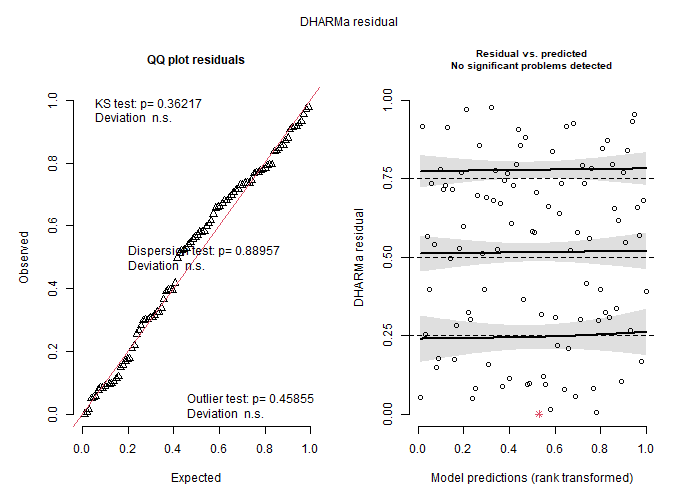

In [95]:
%%R -w 700 -h 500
X <- cbind(1, x1, x2)
beta <- coef(fmwrong)

newY <- replicate(326, {as.numeric(X %*% beta) + rnorm(100, 0, 0.2034)})

simsOwn <- createDHARMa(simulatedResponse=newY, observedResponse=y, fittedPredictedResponse=predict(fmwrong))
plot(simsOwn)

## 5 Exercise 5: DHARMa for discrete data
So far we looked at continuous data. But if we have binary outcomes, the simulations also will only be 0s and 1s, and no quantiles can be computed. So how does DHARMa handle that?

First see that it does, using the `TitanicSurvival` data (from **effects**) and a complex model with interactions.

In [97]:
%%R
install.packages("effects")
library(effects)


R[write to console]: Warning:
R[write to console]:  unable to access index for repository https://mirror.dogado.de/cran/src/contrib:
  cannot open URL 'https://mirror.dogado.de/cran/src/contrib/PACKAGES'

R[write to console]: Warning:
R[write to console]:  unable to access index for repository https://mirror.dogado.de/cran/bin/windows/contrib/4.1:
  cannot open URL 'https://mirror.dogado.de/cran/bin/windows/contrib/4.1/PACKAGES'

Exception ignored from cffi callback <function _consolewrite_ex at 0x000001FF7F650720>:
Traceback (most recent call last):
  File "C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\rpy2\rinterface_lib\callbacks.py", line 133, in _consolewrite_ex
    s = conversion._cchar_to_str_with_maxlen(buf, n, _CCHAR_ENCODING)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ia1015\.conda\envs\envstats2\Lib\site-packages\rpy2\rinterface_lib\conversion.py", line 138, in _cchar_to_str_with_maxlen
    s = ffi.string(c, maxlen).decod

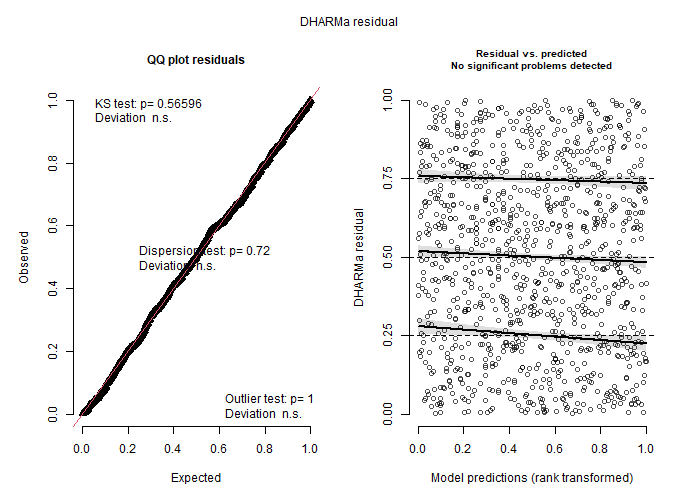

In [99]:
%%R -w 700 -h 500
fti <- glm(survived ~ (age + sex + passengerClass)^2, data=TitanicSurvival, family=binomial)
simsTi <- simulateResiduals(fti, plot=T)

It does work fine.<br>
But how? Well, the vignette of the DHARMa package is a bit thin on explanations, so you have to look at the
cited paper (Dunn, K. P., and Smyth, G. K. (1996). Randomized quantile residuals. Journal of Computational and
Graphical Statistics 5, 1-10.). The key idea is to put noise on both observed and simulated 0/1s, and thereby make
them continuous, and then proceed as above.
If you want, you can do that and compare your results with that of DHARMa. Note that typically we would
uniform noise (U(-0.5, 0.5)) to both observations and simulated data before computing the quantiles (see code of
getQuantile).